# Discovering dimensionless groups for Rayleigh-Benard convection

An executable example of the complete discovery workflow: **processed observations -> dimensional prior learning -> candidate dimensionless groups -> product-exponent optimization -> Nusselt-number prediction -> physical interpretation**.

The case describes heat transfer in Rayleigh-Benard convection. The inputs are layer height $h$, temperature difference $\Delta T$, thermal conductivity $\lambda$, gravity $g$, thermal expansion coefficient $\alpha$, kinematic viscosity $\nu$ and thermal diffusivity $\kappa$. The response is the Nusselt number $Nu$.

**Run every cell in order.** The default `demo` profile trains a fresh prior model for 300 epochs and runs the released optimizer on all 182 observations. Set `PROFILE = "full"` to use 3,000 training epochs. No pretrained model is needed. The learned prior and candidate groups are computed before introducing the classical dimensionless groups for interpretation.

The saved outputs, tables and figures can be previewed on GitHub. Execute the notebook in a local Jupyter/VS Code kernel or in [Google Colab](https://research.google.com/colaboratory/faq.html).

## 1. Locate the release and install missing dependencies

Keep this notebook beside `case_workflow.py`, `knowledge_aware_learning.py`, `parameter_optimize.py`, `settings.json`, `prior_knowledge_database/` and `example_processed_data/`. The initialization supports both a repository containing `Upload_version/` and a repository with the release files at its root.

In a fresh Colab runtime, fill in `REPOSITORY_URL` and `REPOSITORY_BRANCH` in the first code cell so it can clone the published repository. Leave the URL empty if the release files are already available. Opening a notebook in Colab does not automatically download its neighboring files. Existing packages are reused; only missing dependencies are installed.

In [ ]:
from pathlib import Path
import os
import sys
import shutil
import subprocess
import importlib.util

# Fill in the published repository URL before sharing a one-click online example.
REPOSITORY_URL = ""
REPOSITORY_BRANCH = "main"

required_files = ("case_workflow.py", "knowledge_aware_learning.py", "parameter_optimize.py", "settings.json")

def is_release(path):
    return (all((path / name).is_file() for name in required_files)
            and (path / "example_processed_data/benard/data.npz").is_file()
            and (path / "prior_knowledge_database").is_dir())

def locate_release(start):
    for parent in (start, *start.parents):
        for candidate in (parent / "Upload_version", parent):
            if is_release(candidate):
                return candidate.resolve()
    return None

RELEASE_ROOT = locate_release(Path.cwd())
if RELEASE_ROOT is None:
    checkout = Path.cwd() / "dimensionless_example_repository"
    if not checkout.exists():
        if not REPOSITORY_URL:
            raise RuntimeError("Set REPOSITORY_URL to the public GitHub repository, then rerun this cell. "
                               "The Python files and datasets must accompany the notebook.")
        if shutil.which("git") is None:
            raise RuntimeError("Git is needed to clone the release in this runtime.")
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPOSITORY_BRANCH,
                        REPOSITORY_URL, str(checkout)], check=True)
    RELEASE_ROOT = locate_release(checkout)
    if RELEASE_ROOT is None:
        raise FileNotFoundError("The checkout does not contain the expected release files and Rayleigh-Benard data.")

packages = {"numpy": "numpy", "torch": "torch", "matplotlib": "matplotlib", "tqdm": "tqdm"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)

sys.dont_write_bytecode = True
sys.path.insert(0, str(RELEASE_ROOT))
os.chdir(RELEASE_ROOT)
print("Release files found; dependencies are ready.")

Release files found; dependencies are ready.


## 2. Configuration and display helpers

`demo` and `full` use all observations and the same rational-exponent search and polynomial-regression functions; only their training budgets differ. Outputs are isolated under `results_save/benard_notebook/<profile>/`, separate from the Rayleigh notebook and command-line results. Set `FORCE_RETRAIN=False` to load this notebook's compatible checkpoint on a later run.

Python, NumPy and PyTorch are seeded. The released 80/20 regression split uses seed 42. Numerical training results can vary across devices or library versions. The exponent classifier is supervised by prior dimensionless quantities; it does not train on the numerical Bénard inputs or Nusselt response.

In [ ]:
import contextlib
import copy
import html
import io
import json
import math
import re
import time
from unittest.mock import patch

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display, FileLink
import knowledge_aware_learning as knowledge
import case_workflow as workflow
import parameter_optimize as optimize

get_ipython().run_line_magic("matplotlib", "inline")
for module in (knowledge, workflow, optimize):
    assert Path(module.__file__).resolve().parent == RELEASE_ROOT, "Restart the kernel to use the release modules."

PROFILE = "demo"                 # "demo": 300 epochs; "full": 3000 epochs
FORCE_RETRAIN = True
SEED = 42
assert PROFILE in {"demo", "full"}
torch.set_num_threads(min(2, os.cpu_count() or 1))
knowledge.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.constrained_layout.use": True})

RUN_DIR = RELEASE_ROOT / "results_save" / "benard_notebook" / PROFILE
RUN_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

with patch.object(sys, "argv", ["parameter_optimize.py", "benard"]):
    args = optimize.parse_args()
args.data_dir = str(RELEASE_ROOT / "example_processed_data")
args.prior_dir = str(RELEASE_ROOT / "prior_knowledge_database")
args.checkpoint_dir = "model_save"  # Relative to RUN_DIR inside the execution contexts below.
args.epochs = 300 if PROFILE == "demo" else 3000
args.force_retrain = FORCE_RETRAIN
args.force_retain = False
args.output_index = 0
args.target_transform = "auto_log"

@contextlib.contextmanager
def in_directory(path):
    previous = Path.cwd()
    os.chdir(path)
    try:
        yield
    finally:
        os.chdir(previous)

def table(headers, rows):
    def cell(value):
        return html.escape(str(value))
    markup = "<table><thead><tr>" + "".join(f"<th>{cell(h)}</th>" for h in headers) + "</tr></thead><tbody>"
    markup += "".join("<tr>" + "".join(f"<td>{cell(v)}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(markup + "</tbody></table>"))

def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / name, dpi=160, bbox_inches="tight")
    plt.show()

timings = {}
table(["Setting", "Value"], [
    ["Profile / epochs", f"{PROFILE} / {args.epochs}"],
    ["Device", "CUDA" if torch.cuda.is_available() else "CPU"],
    ["Numerical data", "All 182 observations before validity filtering"],
    ["Candidate count / max polynomial degree", f"{args.top_k} / {args.polynomial_max_degree}"],
    ["R2 threshold", args.r2_threshold],
    ["Versions", f"Python {sys.version.split()[0]}; NumPy {np.__version__}; PyTorch {torch.__version__}"],
])

Setting,Value
Profile / epochs,demo / 300
Device,CUDA
Numerical data,All 182 observations before validity filtering
Candidate count / max polynomial degree,10 / 5
R2 threshold,0.92
Versions,Python 3.12.7; NumPy 1.26.4; PyTorch 2.3.1


## 3. Inspect the convection dataset and dimension matrix

`load_case_from_settings()` reads `example_processed_data/benard/sample.json`, `metadata.json` and `data.npz`. The archive contains:

- `X`: 182 observations with columns **`[h, delta_T, lambda, g, alpha, nu, kappa]`**.
- `Y`: the supplied Nusselt response, with shape `(182, 1)`.
- `D_in`: the input dimension matrix, with shape `(4, 7)` and row order **`[L, T, M, Theta]`**.

The exported response was computed during preprocessing as $Nu=q h/(\lambda\Delta T)$ from the source heat-transfer data. The processed archive already contains this normalization; the raw heat-transfer column is not needed to run this example.

The input matrix has dimensional rank four, permitting three independent dimensionless products. Thermal conductivity is the only input carrying the mass dimension. Therefore every dimensionally valid product of these seven inputs must give `lambda` exponent zero. This is a property of the supplied variable set: conductivity is still involved in the earlier normalization of the response.

Array,Shape,Meaning
X,"(182, 7)","h, delta_T, lambda, g, alpha, nu, kappa"
Y,"(182, 1)",Nusselt number Nu
D_in,"(4, 7)","Rows: ['L', 'T', 'M', 'Theta']"


Input,Stored unit,Minimum,Maximum
h,m,0.125,0.2
delta_T,K,0.0017,0.92
lambda,W m^-1 K^-1,0.0014264,21.547
g,m s^-2,9.81,9.81
alpha,K^-1,0.072416,2758.6
nu,m^2 s^-1,3.5048e-08,0.0015276
kappa,m^2 s^-1,2.381e-09,0.00228


Dimension,h,delta_T,lambda,g,alpha,nu,kappa
L,1.0,0.0,1.0,1.0,0.0,2.0,2.0
T,0.0,0.0,-3.0,-2.0,0.0,-1.0,-1.0
M,0.0,0.0,1.0,0.0,0.0,0.0,0.0
Theta,0.0,1.0,-1.0,0.0,-1.0,0.0,0.0


Nu range: 1.01 to 6890; max/min = 6821.78


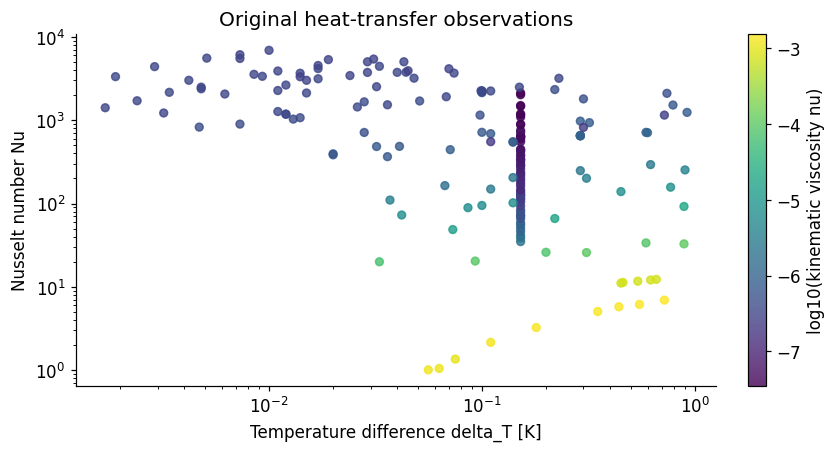

In [ ]:
sample, case_data = optimize.load_case_from_settings(args)
X = np.asarray(case_data["X"], dtype=float)
Y = np.asarray(case_data["Y"], dtype=float).reshape(-1)
D_in = np.asarray(case_data["D_in"], dtype=float)
metadata = case_data["metadata"]
symbols = [variable["symbol"] for variable in sample["variables"]]
assert symbols == ["h", "delta_T", "lambda", "g", "alpha", "nu", "kappa"]
assert X.shape == (182, 7) and Y.shape == (182,)
assert np.isfinite(X).all() and np.isfinite(Y).all()
assert (X > 0).all() and (Y > 0).all()
expected_D = np.array([[v["dimension_vector"][base] for v in sample["variables"]]
                       for base in metadata["row_dims"]])
np.testing.assert_allclose(D_in, expected_D)
assert np.linalg.matrix_rank(D_in) == 4

table(["Array", "Shape", "Meaning"], [
    ["X", X.shape, ", ".join(symbols)], ["Y", case_data["Y"].shape, "Nusselt number Nu"],
    ["D_in", D_in.shape, f"Rows: {metadata['row_dims']}"],
])
table(["Input", "Stored unit", "Minimum", "Maximum"], [
    [v["symbol"], v["unit"], f"{X[:, j].min():.5g}", f"{X[:, j].max():.5g}"]
    for j, v in enumerate(sample["variables"])
])
table(["Dimension", *symbols], [[base, *row] for base, row in zip(metadata["row_dims"], D_in)])
print(f"Nu range: {Y.min():.6g} to {Y.max():.6g}; max/min = {Y.max()/Y.min():.6g}")

fig, ax = plt.subplots(figsize=(7.5, 4))
points = ax.scatter(X[:, 1], Y, c=np.log10(X[:, 5]), s=26, alpha=0.8, cmap="viridis")
ax.set(xscale="log", yscale="log", xlabel="Temperature difference delta_T [K]", ylabel="Nusselt number Nu",
       title="Original heat-transfer observations")
fig.colorbar(points, ax=ax, label="log10(kinematic viscosity nu)")
save_figure(fig, "01_original_data.png")

## 4. Construct the dimensional prior training set

`load_prior_knowledge_database(..., selected_training_case="benard")` removes the loader's named Rayleigh, heat-instability Rayleigh, Prandtl and Nusselt entries before training. `filter_trainable_samples()` then rejects records with invalid labels or nonzero `D @ alpha`.

Each prior record is a variable set with exponent labels describing a known dimensionless product. Only the seven base-dimensional exponents are neural input features. Variable names, physical descriptions and numerical convection observations are not features. The name-based exclusions do not guarantee removal of every algebraically related prior quantity.

In [ ]:
all_prior_count = len(list(Path(args.prior_dir).glob("*.json")))
prior_samples = knowledge.load_prior_knowledge_database(args.prior_dir, selected_training_case="benard")
train_samples, skipped_samples = knowledge.filter_trainable_samples(prior_samples)
vocabs = knowledge.build_vocabs(train_samples + [sample])
table(["Prior-data check", "Records"], [
    ["JSON records in release", all_prior_count],
    ["Excluded by Benard case names", all_prior_count - len(prior_samples)],
    ["Skipped after dimensional validation", len(skipped_samples)],
    ["Used for neural training", len(train_samples)],
])
encoded_inputs = np.array([knowledge.encode_variable(v, vocabs) for v in sample["variables"]])
table(["Variable", *vocabs["base_dims"]], [[symbol, *row] for symbol, row in zip(symbols, encoded_inputs)])
print("Available exponent classes:", ", ".join(knowledge.format_alpha_value(a) for a in knowledge.ALPHA_VALUES))

[Data] training_case=benard | excluded prior samples=8


Prior-data check,Records
JSON records in release,1310
Excluded by Benard case names,8
Skipped after dimensional validation,22
Used for neural training,1280


Variable,M,L,T,I,Theta,N,J
h,0.0,1.0,0.0,0.0,0.0,0.0,0.0
delta_T,0.0,0.0,0.0,0.0,1.0,0.0,0.0
lambda,1.0,1.0,-3.0,0.0,-1.0,0.0,0.0
g,0.0,1.0,-2.0,0.0,0.0,0.0,0.0
alpha,0.0,0.0,0.0,0.0,-1.0,0.0,0.0
nu,0.0,2.0,-1.0,0.0,0.0,0.0,0.0
kappa,0.0,2.0,-1.0,0.0,0.0,0.0,0.0


Available exponent classes: -5, -4, -3, -5/2, -7/3, -2, -5/3, -3/2, -4/3, -5/4, -1, -3/4, -2/3, -3/5, -1/2, -2/5, -1/3, -1/4, -1/5, -1/10, 0, 1/10, 1/5, 1/4, 1/3, 1/2, 3/5, 2/3, 3/4, 9/10, 1, 4/3, 3/2, 5/3, 2, 3, 4, 6


## 5. Train the exponent model

`load_prediction_model()` calls `train_model()` to train the released `SetTransformerExponentClassifier`: three attention blocks, hidden dimension 128, four attention heads, AdamW, and masked cross-entropy loss. A checkpoint records the lowest **training** loss; this curve is not a Nusselt-response validation score.

The notebook uses its own checkpoint directory. The next optimization stage loads this exact checkpoint instead of training a second model.

[Data] training_case=benard | excluded prior samples=8

[Train] Using device: cuda

[Train] Epoch 0001 | loss = 3.4857 | best = 3.4857

G:\software\Anaconda3\Lib\site-packages\torch\nn\functional.py:5504: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:455.)
  attn_output = scaled_dot_product_attention(q, k, v, attn_mask, dropout_p, is_causal)


[Train] Epoch 0050 | loss = 1.5503 | best = 1.5503

...

[Train] Epoch 0200 | loss = 0.9094 | best = 0.9094

[Train] Epoch 0250 | loss = 0.7800 | best = 0.7719

[Train] Epoch 0300 | loss = 0.6792 | best = 0.6710

[Train] Best checkpoint saved to model_save\case_specific\benard\knowledge_aware_learning_benard_best.pt | loss = 0.6710

[Model] Using model: model_save\case_specific\benard\knowledge_aware_learning_benard_best.pt

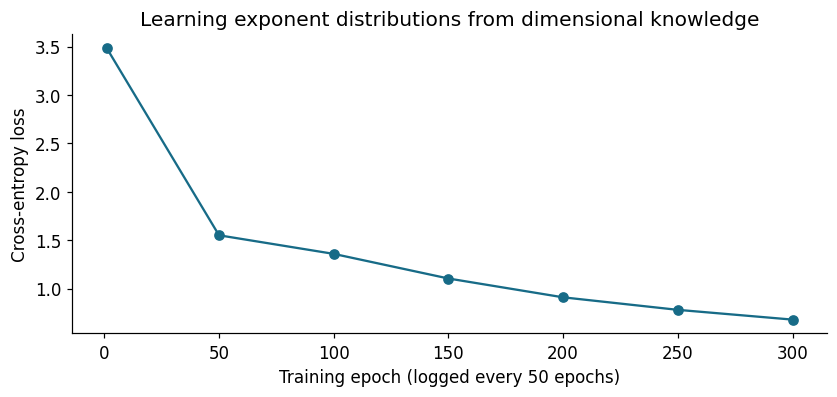

In [ ]:
training_buffer = io.StringIO()
started = time.perf_counter()
knowledge.set_seed(SEED)
with in_directory(RUN_DIR), contextlib.redirect_stdout(optimize.TeeOutput(sys.stdout, training_buffer)):
    model, vocabs = workflow.load_prediction_model(args, sample)
timings["Prior model training/loading"] = time.perf_counter() - started
training_text = training_buffer.getvalue()
(RUN_DIR / "training_log.txt").write_text(training_text, encoding="utf-8")
history = [(int(epoch), float(loss)) for epoch, loss in re.findall(
    r"\[Train\] Epoch (\d+) \| loss = ([0-9.eE+-]+)", training_text)]
if history:
    epoch_values, loss_values = np.array(history).T
    fig, ax = plt.subplots(figsize=(7.5, 3.5))
    ax.plot(epoch_values, loss_values, "o-", color="#176b87")
    ax.set(xlabel="Training epoch (logged every 50 epochs)", ylabel="Cross-entropy loss",
           title="Learning exponent distributions from dimensional knowledge")
    save_figure(fig, "02_training_loss.png")
else:
    print("An existing checkpoint was loaded; no new training curve was generated.")

## 6. Decode and rank dimensionless candidates

`predict_distributions()` produces exponent probabilities. `evaluate_subset_candidates()` tries variable subsets and invokes `constrained_decode()` to enforce $D\alpha=0$. A zero exponent omits a variable. Subset/complexity penalties rank the valid candidates, and a Buckingham–Pi fallback is available when the likely exponent choices contain no valid group.

Candidate ranking is based on the dimensional prior, not response-fit R². Canonicalization reduces proportional exponent vectors and fixes their overall sign; equivalent powers may appear under different conventional names.

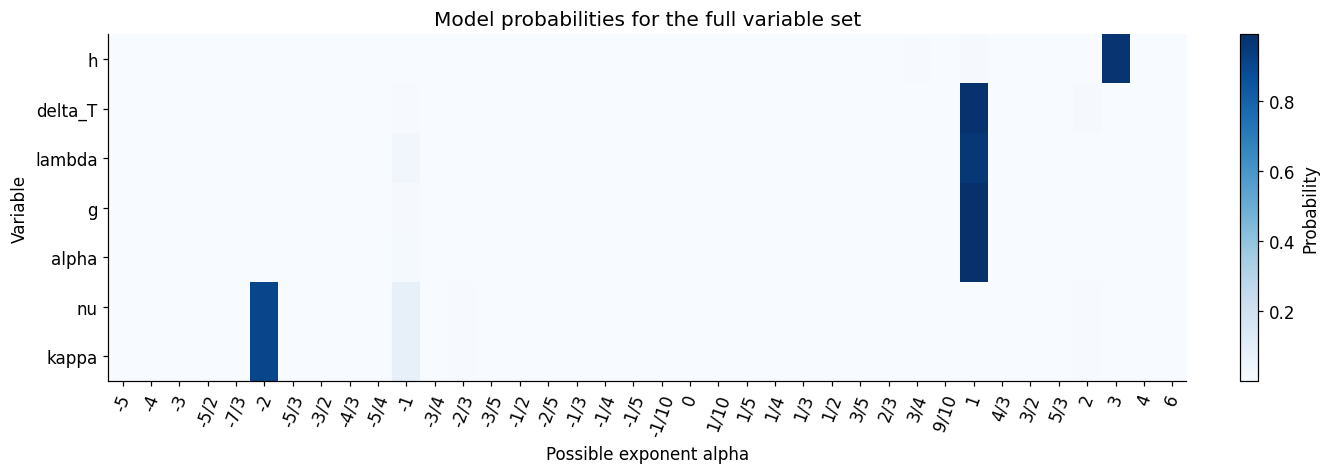


Evaluating subsets:   0%|          | 0/120 [00:00<?, ?subset/s]


Evaluating subsets:  52%|█████▏    | 62/120 [00:00<00:00, 586.01subset/s]


Evaluating subsets: 100%|██████████| 120/120 [00:06<00:00, 19.74subset/s]

[Cache] Saved raw_candidates to results_save\benard\raw_candidates.pkl


Rank,Formula,alpha in stored input order,Prior score,Source
1,delta_T * alpha,"[0, 1, 0, 0, 1, 0, 0]",-1.5699,model_subset
2,nu / (kappa),"[0, 0, 0, 0, 0, 1, -1]",-2.0046,model_subset
3,h^3 * delta_T * g * alpha / (nu^2),"[3, 1, 0, 1, 1, -2, 0]",-2.1961,model_subset
4,h^3 * delta_T * g * alpha / (kappa^2),"[3, 1, 0, 1, 1, 0, -2]",-2.1961,model_subset
5,delta_T * alpha * nu / (kappa),"[0, 1, 0, 0, 1, 1, -1]",-2.8265,model_subset
6,delta_T * alpha * kappa / (nu),"[0, 1, 0, 0, 1, -1, 1]",-2.8265,model_subset
7,h^3 * g / (nu^2),"[3, 0, 0, 1, 0, -2, 0]",-2.9172,model_subset
8,h^3 * g / (kappa^2),"[3, 0, 0, 1, 0, 0, -2]",-2.9172,model_subset
9,h^3 * delta_T * g * alpha / (nu * kappa),"[3, 1, 0, 1, 1, -1, -1]",-3.5354,model_subset
10,h^3 * g / (delta_T * alpha * nu^2),"[3, -1, 0, 1, -1, -2, 0]",-7.0502,model_subset


In [ ]:
probabilities = knowledge.predict_distributions(model, sample, vocabs)
fig, ax = plt.subplots(figsize=(12, 4.2))
image = ax.imshow(probabilities, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(symbols)), symbols)
ax.set_xticks(range(len(knowledge.ALPHA_VALUES)),
              [knowledge.format_alpha_value(a) for a in knowledge.ALPHA_VALUES], rotation=70)
ax.set(xlabel="Possible exponent alpha", ylabel="Variable", title="Model probabilities for the full variable set")
fig.colorbar(image, ax=ax, label="Probability")
save_figure(fig, "03_exponent_probabilities.png")

source_top_k = max(args.top_k, args.independent_rank_top_n)
if args.rank_source_top_k is not None:
    source_top_k = max(int(args.rank_source_top_k), args.independent_rank_top_n)
started = time.perf_counter()
raw_candidates = knowledge.evaluate_subset_candidates(
    model, sample, vocabs, top_n=source_top_k * 3,
    subset_size_penalty=args.subset_size_penalty, show_progress=True,
)
timings["Candidate generation"] = time.perf_counter() - started
candidates, duplicates = optimize.deduplicate_candidates_by_alpha(raw_candidates)
candidates = candidates[:source_top_k]
assert candidates, "No valid dimensionless candidate was generated."
for candidate in candidates:
    np.testing.assert_allclose(D_in @ np.array(candidate["full_alpha"], dtype=float), 0, atol=1e-8)
with in_directory(RUN_DIR):
    optimize.save_raw_candidates_cache(args, source_top_k, raw_candidates)
table(["Rank", "Formula", "alpha in stored input order", "Prior score", "Source"], [
    [rank, c["formula"], list(c["full_alpha"]), f"{c['score']:.4f}", c.get("source", "model_subset")]
    for rank, c in enumerate(candidates, 1)
])
assert all(abs(float(c["full_alpha"][2])) < 1e-8 for c in candidates), "Mass balance requires zero conductivity exponent."


## 7. Prepare log-inputs, the response and independent groups

For candidate $\Pi_j$, `compute_log_pi_matrix()` evaluates $\log\Pi_j=\sum_i a_{ji}\log x_i$. Active inputs must be positive, and the pipeline retains the intersection of valid rows across candidates. All supplied Bénard input values are positive.

`select_target(..., transform="auto_log")` uses **`log(Nu)`** because every response is positive and `max(Nu)/min(Nu) > 100`. The reported optimization R² is therefore on the log-response scale. Exponentiating the fitted response produces predictions in the original Nusselt scale.

`select_independent_rank_candidates()` retains independent exponent vectors, and `random_regression_split()` applies the released 80/20 split with seed 42. The split called "test" in the code is reused to select exponent products, polynomial degrees and group pairs; it is a model-selection split, not an untouched final evaluation set.

In [ ]:
log_pi_all, valid_pi = optimize.compute_log_pi_matrix(X, candidates)
target_all, valid_y, target_transform = optimize.select_target(case_data["Y"], args.output_index, args.target_transform)
valid = valid_pi & valid_y & np.isfinite(log_pi_all).all(axis=1) & np.isfinite(target_all)
valid_original_rows = np.flatnonzero(valid)
log_pi, target = log_pi_all[valid], target_all[valid]
train_indices, test_indices = optimize.random_regression_split(len(target), train_fraction=0.8, random_seed=42)
selected, dependent = optimize.select_independent_rank_candidates(
    candidates, max_rank=min(args.independent_rank_top_n, source_top_k))
assert selected
table(["Preprocessing", "Count / value"], [
    ["Original observations", len(Y)], ["Valid observations", int(valid.sum())],
    ["Rows excluded by candidate/response preprocessing", int((~valid).sum())],
    ["Training / selection-test observations", f"{len(train_indices)} / {len(test_indices)}"],
    ["Response transform", target_transform], ["Independent base groups", len(selected)],
])
table(["Base group", "Formula", "alpha"], [
    [optimize.candidate_label(i), candidates[i]["formula"], list(candidates[i]["full_alpha"])]
    for i in selected
])
assert target_transform == "log"
assert len(target) == 182


[Target transform] auto_log: positive=True, max/min=6821.78, threshold=1e2 -> use log
[Target transform] log applied to target.


Preprocessing,Count / value
Original observations,182
Valid observations,182
Rows excluded by candidate/response preprocessing,0
Training / selection-test observations,145 / 37
Response transform,log
Independent base groups,3


Base group,Formula,alpha
Pi_1,delta_T * alpha,"[0, 1, 0, 0, 1, 0, 0]"
Pi_2,nu / (kappa),"[0, 0, 0, 0, 0, 1, -1]"
Pi_3,h^3 * delta_T * g * alpha / (nu^2),"[3, 1, 0, 1, 1, -2, 0]"


## 8. Run the released product-exponent optimization

For independent groups $\Pi_j$, search

$$\Pi_{\mathrm{total}}=\prod_j\Pi_j^{\beta_j},\qquad
\gamma_i=\sum_j\beta_j\alpha_{ji}.$$

The released `run_logged_main()` executes these stages:

1. Select independent candidate exponent vectors.
2. `search_classic_exponent_products()`: search the configured rational `beta` grid and screen linear fits in `log(Pi_total)`.
3. `refine_with_polynomial()`: refine polynomials in `log(Pi_total)`.
4. If the Step-3 score reaches the threshold, `refine_with_raw_pi_polynomial()` tests powers/reciprocals and polynomial fits in raw `Pi_total`.
5. If the Step-3 score is below threshold, `search_two_pi_models()` selects a pair from four prescribed features and fits a polynomial in their logarithms.

One-group ranking uses selection-test R² minus the configured exponent-complexity penalty. This cell reuses the checkpoint and candidate cache produced above; it does not inject the classical Rayleigh or Prandtl reference groups. Expand the report to inspect every executed stage and the final selection.

In [ ]:
optimization_args = copy.copy(args)
optimization_args.force_retrain = False
optimization_args.force_retain = False
optimization_buffer = io.StringIO()
started = time.perf_counter()
with in_directory(RUN_DIR), contextlib.redirect_stdout(optimization_buffer):
    optimize.run_logged_main(optimization_args)
timings["Product-exponent optimization"] = time.perf_counter() - started
optimization_text = optimization_buffer.getvalue()
safe_report = optimization_text.replace(str(RELEASE_ROOT), "<release>")
display(HTML("<details><summary><b>Complete optimization report (click to expand)</b></summary><pre>"
             + html.escape(safe_report) + "</pre></details>"))

import pickle
result_path = RUN_DIR / "results_save/benard/parameter_optimize_result.pkl"
with result_path.open("rb") as stream:
    payload = pickle.load(stream)
result = payload["result"]
row = result["row"]
assert payload["selected"] == selected
assert [c["full_alpha"] for c in payload["candidates"]] == [c["full_alpha"] for c in candidates]
table(["Final selection", "Value"], [
    ["Number of groups", result["kind"]], ["Selected stage", result["selected_step"]],
    ["Metric key", result["metric_key"]],
    ["Polynomial degree", row.get("raw_poly_degree", row.get("poly_degree", 1))],
])


Step 2 classic exponent search:   0%|          | 0/1331 [00:00<?, ?item/s]


Step 2 classic exponent search: 100%|██████████| 1331/1331 [00:00<00:00, 28147.56item/s]


Step 3 polynomial refinement:   0%|          | 0/665 [00:00<?, ?item/s]


Step 3 polynomial refinement:  61%|██████    | 405/665 [00:00<00:00, 4030.04item/s]


Step 3 polynomial refinement: 100%|██████████| 665/665 [00:00<00:00, 4010.83item/s]


Step 4 raw-pi polynomial:   0%|          | 0/10 [00:00<?, ?item/s]


Step 4 raw-pi polynomial: 100%|██████████| 10/10 [00:00<00:00, 3314.08item/s]

Final selection,Value
Number of groups,one
Selected stage,3
Metric key,poly_r2
Polynomial degree,5


## 9. Recover the selected response model and verify its predictions

The optimizer's compact pickle stores groups, scores and the selected polynomial degree, but omits the complete regression coefficients. This cell refits **only the selected relation**, with the released fitting functions on the exact same training rows, and checks that its log-response selection-test R² reproduces the stored score.

A one-group model uses either `log(Pi_total)` or raw `Pi_total` as its regression coordinate. A two-group model uses the logarithms of the chosen groups. The polynomial is expressed in standardized features. Its output is `log(Nu)` here, so the final Nusselt prediction is `exp(polynomial)`.

Both log-response and original-response metrics are displayed. An R² reported for `log(Nu)` must not be interpreted as an R² for raw `Nu`.

Discovered group,Formula,alpha in stored input order
Pi_1,h^3 * delta_T * g * alpha / (nu * kappa),"[3.0, 1.0, 0.0, 1.0, 1.0, -1.0, -1.0]"


Fit quantity,Value
Regression input,log(Pi_total)
Response scale,log
Train R2,0.99912941
Selection-test R2 on log(Nu),0.99838919
Selection-test R2 on raw Nu,0.99464003
Selection-test MAE in Nu,71.798297


Polynomial: log(Nu_hat) = sum(coefficient * product(z_j ** power_j)); z = (feature - mean) / scale
Feature mean: [26.03910667]
Feature scale: [5.64445401]


Powers of standardized coordinates,Coefficient
"(0,)",5.896745931
"(1,)",2.06187693
"(2,)",0.1575926
"(3,)",-0.1498942957
"(4,)",0.0002687823846
"(5,)",0.02786776605


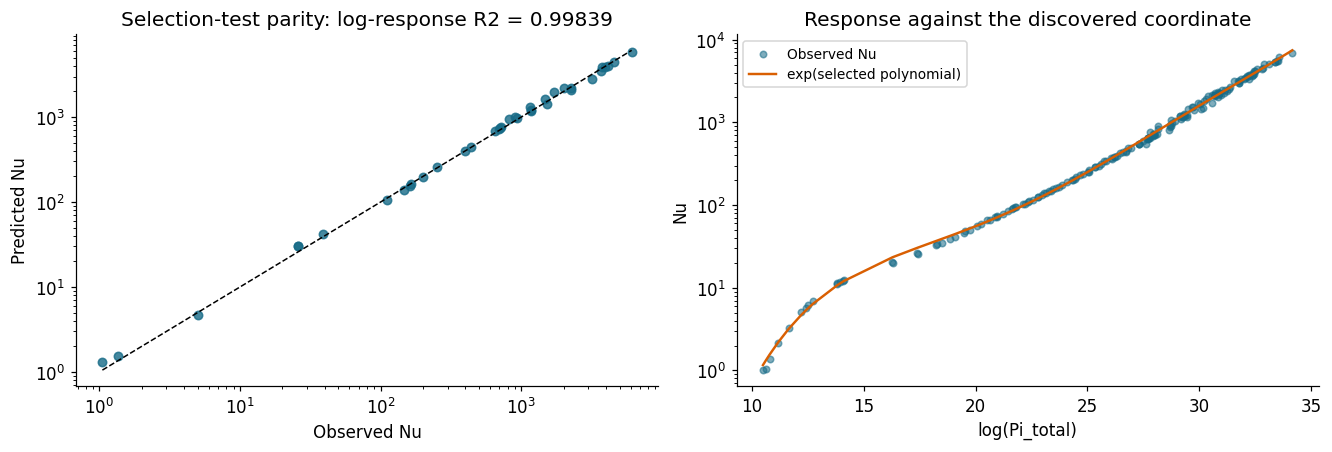

In [ ]:
if result["kind"] == "one":
    beta = row["beta"]
    gamma = np.array(optimize.combined_alpha_for_search(candidates, selected, beta), dtype=float)
    group_alphas = gamma[None, :]
    group_formulas = [knowledge.alpha_to_formula(sample, gamma)]
    group_logs = optimize.total_log_pi(log_pi[:, selected], beta)[:, None]
    raw_input = result["metric_key"] == "raw_poly_r2"
    regression_features = np.exp(np.clip(group_logs, -700, 700)) if raw_input else group_logs
    degree = int(row.get("raw_poly_degree", 1) if raw_input else row.get("poly_degree", 1))
    fit = optimize.fit_poly_1d_train_test(
        regression_features[train_indices, 0], target[train_indices],
        regression_features[test_indices, 0], target[test_indices], degree=degree)
    assert fit is not None
    feature_mean = np.array([fit["x_mean"]])
    feature_scale = np.array([fit["x_scale"]])
    standardized = (regression_features - feature_mean) / feature_scale
    design = optimize.design_matrix_1d(standardized[:, 0], degree)
    powers = [(power,) for power in range(degree + 1)]
    recorded_r2 = row.get("raw_poly_test_r2") if raw_input else row.get("poly_test_r2", row["linear_test_r2"])
    regression_input = "Pi_total" if raw_input else "log(Pi_total)"
else:
    assert row.get("mode") == "selected_step3_raw_linear", "This notebook expects the current released two-group search."
    group_alphas = np.array(row["pi_alphas"], dtype=float)
    group_formulas = list(row["pi_formulas"])
    regression_features = np.column_stack([
        optimize.step6_log_pi_values(log_pi, spec) for spec in row["feature_specs"]])
    degree = int(row["poly_degree"])
    fit = optimize.fit_poly_nd_train_test(
        regression_features[train_indices], target[train_indices],
        regression_features[test_indices], target[test_indices], degree=degree)
    assert fit is not None
    feature_mean, feature_scale = fit["mean"], fit["scale"]
    design, powers = optimize.design_matrix_nd((regression_features - feature_mean) / feature_scale, degree)
    recorded_r2 = row["poly_test_r2"]
    regression_input = "log(Pi_1), log(Pi_2)"

prediction_transformed = design @ fit["coef"]
prediction = np.exp(prediction_transformed) if target_transform == "log" else prediction_transformed
np.testing.assert_allclose(fit["test_r2"], recorded_r2, atol=1e-7, rtol=1e-7)
np.testing.assert_allclose(D_in @ group_alphas.T, 0, atol=1e-8)

table(["Discovered group", "Formula", "alpha in stored input order"], [
    [f"Pi_{i + 1}", formula, alpha.tolist()]
    for i, (formula, alpha) in enumerate(zip(group_formulas, group_alphas))
])
table(["Fit quantity", "Value"], [
    ["Regression input", regression_input], ["Response scale", target_transform],
    ["Train R2", f"{fit['train_r2']:.8f}"],
    ["Selection-test R2 on log(Nu)", f"{fit['test_r2']:.8f}"],
    ["Selection-test R2 on raw Nu", f"{optimize.r2_score_np(Y[valid][test_indices], prediction[test_indices]):.8f}"],
    ["Selection-test MAE in Nu", f"{np.mean(np.abs(Y[valid][test_indices] - prediction[test_indices])):.8g}"],
])
print("Polynomial: log(Nu_hat) = sum(coefficient * product(z_j ** power_j)); z = (feature - mean) / scale")
print("Feature mean:", feature_mean)
print("Feature scale:", feature_scale)
table(["Powers of standardized coordinates", "Coefficient"], [
    [tuple(power), f"{coefficient:.10g}"] for power, coefficient in zip(powers, fit["coef"])
])


plot_test = test_indices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(Y[valid][plot_test], prediction[plot_test], s=30, alpha=0.8, color="#176b87")
limits = [min(Y[valid][plot_test].min(), prediction[plot_test].min()),
          max(Y[valid][plot_test].max(), prediction[plot_test].max())]
axes[0].plot(limits, limits, "k--", lw=1)
axes[0].set(xscale="log", yscale="log", xlabel="Observed Nu", ylabel="Predicted Nu",
            title=f"Selection-test parity: log-response R2 = {fit['test_r2']:.5f}")
if result["kind"] == "one":
    coordinate = regression_features[:, 0]
    axes[1].scatter(coordinate, Y[valid], s=18, alpha=0.55, color="#176b87", label="Observed Nu")
    ordering = np.argsort(coordinate)
    axes[1].plot(coordinate[ordering], prediction[ordering], color="#d95f02", lw=1.6, label="exp(selected polynomial)")
    axes[1].set(xlabel=regression_input, ylabel="Nu", yscale="log", title="Response against the discovered coordinate")
    axes[1].legend(fontsize=9)
else:
    residual = prediction_transformed[plot_test] - target[plot_test]
    axes[1].scatter(prediction_transformed[plot_test], residual, s=30, alpha=0.8, color="#176b87")
    axes[1].axhline(0, color="black", ls="--", lw=1)
    axes[1].set(xlabel="Predicted log(Nu)", ylabel="log-response residual", title="Two-group response fit")
save_figure(fig, "04_discovered_response.png")

## 10. Interpret the discovered groups using convection reference numbers

Only after discovery, introduce conventional reference coordinates:

$$Ra=\frac{g\alpha\Delta T h^3}{\nu\kappa},\qquad
Pr=\frac{\nu}{\kappa},\qquad C_T=\alpha\Delta T.$$

In the stored input order, their exponent vectors are respectively `[3, 1, 0, 1, 1, -1, -1]`, `[0, 0, 0, 0, 0, 1, -1]` and `[0, 1, 0, 0, 1, 0, 0]`. Together these form a basis of the three-dimensional input nullspace. The numerical optimizer was not given these reference vectors.

The interpretation table expresses each selected group as $Ra^a Pr^b C_T^c$ and checks whether the classical Rayleigh direction itself was recovered or lies in the span of the selected groups. A power or reciprocal can describe the same dimensional direction.

There is no exact universal `Nu(Ra, Pr)` expression supplied by this dataset. For context, a **separate diagnostic baseline** fits `log(Nu) = log(A) + b*log(Ra)` on the training rows and evaluates it on the same selection-test rows. This empirical power law is introduced after optimization; it is not substituted for the discovered model or claimed to be an analytical solution.

**Physical interpretation:** The selected group is Ra ** (1); the classical Rayleigh direction was recovered.

Selected group,Power of Ra,Power of Pr,Power of alpha*delta_T
Pi_1,1,0,-3.8573546e-16


Reference direction,In span of selected groups
Ra,True
Pr,False


Post-discovery diagnostic baseline,Value
Training-fit power law,Nu = 0.0694302 * Ra ** (0.333832)
Baseline selection-test R2 on log(Nu),0.99045790
Discovered model selection-test R2 on log(Nu),0.99838919


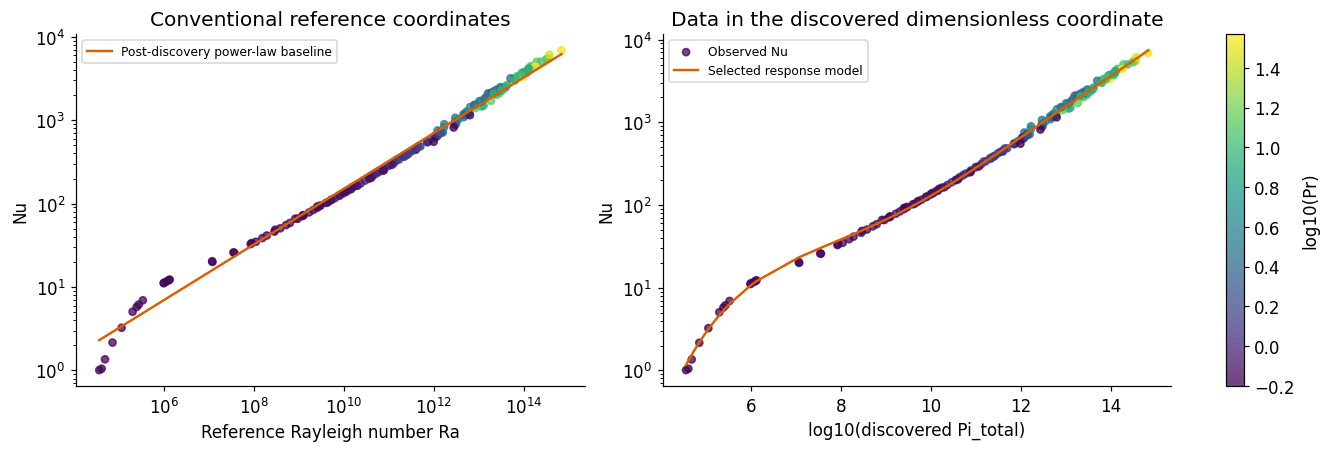

In [ ]:
ra_alpha = np.array([3.0, 1.0, 0.0, 1.0, 1.0, -1.0, -1.0])
pr_alpha = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 1.0, -1.0])
thermal_alpha = np.array([0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0])
reference_basis = np.column_stack([ra_alpha, pr_alpha, thermal_alpha])
np.testing.assert_allclose(D_in @ reference_basis, 0, atol=1e-8)
assert np.linalg.matrix_rank(reference_basis) == X.shape[1] - np.linalg.matrix_rank(D_in)
Ra = X[:, 3] * X[:, 4] * X[:, 1] * X[:, 0]**3 / (X[:, 5] * X[:, 6])
Pr = X[:, 5] / X[:, 6]
reference_weights = np.linalg.lstsq(reference_basis, group_alphas.T, rcond=None)[0]
np.testing.assert_allclose(reference_basis @ reference_weights, group_alphas.T, atol=1e-8)

directions_in_span = {}
for name, vector in [("Ra", ra_alpha), ("Pr", pr_alpha)]:
    coefficients = np.linalg.lstsq(group_alphas.T, vector, rcond=None)[0]
    directions_in_span[name] = bool(np.allclose(group_alphas.T @ coefficients, vector, atol=1e-8))
if result["kind"] == "one":
    ra_power = float(group_alphas[0] @ ra_alpha / (ra_alpha @ ra_alpha))
    recovered_reference = bool(abs(ra_power) > 1e-10 and np.allclose(group_alphas[0], ra_power * ra_alpha, atol=1e-8))
    interpretation = (f"The selected group is Ra ** ({ra_power:g}); the classical Rayleigh direction was recovered."
                      if recovered_reference else
                      "The selected group is a product of the reference coordinates with the exponents reported below.")
else:
    recovered_reference = directions_in_span["Ra"]
    interpretation = ("The Rayleigh direction lies in the span of the two selected groups."
                      if recovered_reference else "The selected pair does not span the classical Rayleigh direction.")
display(Markdown("**Physical interpretation:** " + interpretation))
table(["Selected group", "Power of Ra", "Power of Pr", "Power of alpha*delta_T"], [
    [f"Pi_{i+1}", *[f"{value:.8g}" for value in reference_weights[:, i]]]
    for i in range(group_alphas.shape[0])
])
table(["Reference direction", "In span of selected groups"], list(directions_in_span.items()))

log_Ra = np.log(Ra[valid])
log_Nu = np.log(Y[valid])
baseline = optimize.fit_poly_1d_train_test(log_Ra[train_indices], log_Nu[train_indices],
                                        log_Ra[test_indices], log_Nu[test_indices], degree=1)
assert baseline is not None
baseline_power = float(baseline["coef"][1] / baseline["x_scale"])
baseline_log_prefactor = float(baseline["coef"][0] - baseline_power * baseline["x_mean"])
table(["Post-discovery diagnostic baseline", "Value"], [
    ["Training-fit power law", f"Nu = {np.exp(baseline_log_prefactor):.6g} * Ra ** ({baseline_power:.6g})"],
    ["Baseline selection-test R2 on log(Nu)", f"{baseline['test_r2']:.8f}"],
    ["Discovered model selection-test R2 on log(Nu)", f"{fit['test_r2']:.8f}"],
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
points = axes[0].scatter(Ra, Y, c=np.log10(Pr), s=22, alpha=0.75, cmap="viridis")
ra_grid = np.geomspace(Ra.min(), Ra.max(), 300)
axes[0].plot(ra_grid, np.exp(baseline_log_prefactor + baseline_power * np.log(ra_grid)),
             color="#d95f02", lw=1.6, label="Post-discovery power-law baseline")
axes[0].set(xscale="log", yscale="log", xlabel="Reference Rayleigh number Ra", ylabel="Nu",
            title="Conventional reference coordinates")
axes[0].legend(fontsize=8)
if result["kind"] == "one":
    log_group = optimize.total_log_pi(log_pi[:, selected], row["beta"])
    axes[1].scatter(log_group / np.log(10), Y[valid], c=np.log10(Pr[valid]), s=22,
                    alpha=0.75, cmap="viridis", label="Observed Nu")
    ordering = np.argsort(log_group)
    axes[1].plot(log_group[ordering] / np.log(10), prediction[ordering], color="#d95f02", lw=1.6,
                 label="Selected response model")
    axes[1].set(xlabel="log10(discovered Pi_total)", ylabel="Nu", yscale="log",
                title="Data in the discovered dimensionless coordinate")
    axes[1].legend(fontsize=8)
    fig.colorbar(points, ax=axes, label="log10(Pr)")
else:
    heat = axes[1].scatter(regression_features[:, 0], regression_features[:, 1], c=np.log10(Y[valid]),
                           s=24, alpha=0.8, cmap="magma")
    axes[1].set(xlabel="log(Pi_1)", ylabel="log(Pi_2)", title="Selected two-group coordinates")
    fig.colorbar(points, ax=axes[0], label="log10(Pr)")
    fig.colorbar(heat, ax=axes[1], label="log10(Nu)")
save_figure(fig, "05_physical_interpretation.png")

## 11. Export the fitted model, predictions and reports

The notebook supplements the original optimizer's report with:

- `discovery_summary.json`: the run configuration, physical input order, selected formulas, exponents, metrics, reference-group interpretation and source hashes.
- `response_model.npz`: polynomial coefficients, feature means/scales, monomial powers and physical-variable exponents.
- `predictions.npz`: observed/predicted Nusselt values, regression features, original observation indices and the fixed train/selection-test split.
- The training log, original optimization log/pickles, and five PNG figures.

The learned response relation is an empirical polynomial in the selected coordinate(s), followed by exponentiation to obtain `Nu`. The reference-group comparison and baseline are post-discovery diagnostics. Model-selection scores reuse the selection split; an additional independent dataset would be needed for a final generalization benchmark.

The ZIP archive is created when this notebook runs. GitHub can preview the embedded figures, but generated files become available in the execution runtime rather than automatically being committed to the repository.

In [ ]:
import hashlib
import importlib.metadata

summary = {
    "case": "benard", "profile": PROFILE, "seed": SEED,
    "training_epochs_requested": args.epochs, "force_retrain": FORCE_RETRAIN,
    "original_rows": len(Y), "valid_rows": len(target),
    "train_rows": len(train_indices), "selection_test_rows": len(test_indices),
    "active_variable_order": symbols, "dimension_rows": metadata["row_dims"],
    "group_formulas": group_formulas, "group_alphas": group_alphas.tolist(),
    "kind": result["kind"], "selected_step": result["selected_step"],
    "beta": [str(value) for value in row["beta"]] if result["kind"] == "one" else None,
    "regression_input": regression_input, "response_transform": target_transform,
    "polynomial_degree": degree, "train_r2_log_Nu": float(fit["train_r2"]),
    "selection_test_r2_log_Nu": float(fit["test_r2"]),
    "selection_test_r2_raw_Nu": float(optimize.r2_score_np(Y[valid][test_indices], prediction[test_indices])),
    "selection_test_mae_Nu": float(np.mean(np.abs(Y[valid][test_indices] - prediction[test_indices]))),
    "rayleigh_direction_recovered": recovered_reference,
    "reference_directions_in_span": directions_in_span,
    "group_exponents_in_Ra_Pr_thermal_basis": reference_weights.T.tolist(),
    "physical_interpretation": interpretation,
    "post_discovery_baseline": {"prefactor": float(np.exp(baseline_log_prefactor)),
                                "power": baseline_power, "selection_test_r2_log_Nu": float(baseline["test_r2"])},
    "classic_exponents": [str(value) for value in args.classic_exponents],
    "r2_threshold": args.r2_threshold, "max_polynomial_degree": args.polynomial_max_degree,
    "optimizer_settings": {key: value.replace(str(RELEASE_ROOT), "<release>") if isinstance(value, str) else value
                           for key, value in vars(args).items()},
    "timings_seconds": timings,
    "versions": {name: importlib.metadata.version(name) for name in ("numpy", "torch", "matplotlib")},
    "source_sha256": {name: hashlib.sha256((RELEASE_ROOT / name).read_bytes()).hexdigest()
                      for name in (*required_files, "example_processed_data/benard/data.npz")},
}
(RUN_DIR / "discovery_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
np.savez_compressed(RUN_DIR / "response_model.npz", coefficients=fit["coef"],
                    feature_mean=feature_mean, feature_scale=feature_scale,
                    monomial_powers=np.array(powers, dtype=int), group_alphas=group_alphas,
                    response_transform=np.array(target_transform), regression_input=np.array(regression_input))
np.savez_compressed(RUN_DIR / "predictions.npz", observed=Y[valid], predicted=prediction,
                    observed_log_Nu=target, predicted_log_Nu=prediction_transformed,
                    regression_features=regression_features, original_row_indices=valid_original_rows,
                    train_indices=train_indices, selection_test_indices=test_indices)
table(["Stage", "Elapsed seconds"], [[name, f"{seconds:.2f}"] for name, seconds in timings.items()])
print("Saved to:", RUN_DIR.relative_to(RELEASE_ROOT).as_posix())
print("Exported files:")
for output in sorted(RUN_DIR.rglob("*")):
    if output.is_file():
        print(" ", output.relative_to(RUN_DIR).as_posix())

archive = Path(shutil.make_archive(str(RUN_DIR.parent / f"benard_{PROFILE}_results"), "zip", RUN_DIR))
display(FileLink(archive.relative_to(RELEASE_ROOT).as_posix(), result_html_prefix="Download result archive: "))

Stage,Elapsed seconds
Prior model training/loading,11.55
Candidate generation,6.08
Product-exponent optimization,0.39


Saved to: results_save/benard_notebook/demo
Exported files:
  discovery_summary.json
  figures/01_original_data.png
  figures/02_training_loss.png
  figures/03_exponent_probabilities.png
  figures/04_discovered_response.png
  figures/05_physical_interpretation.png
  model_save/case_specific/benard/knowledge_aware_learning_benard_best.pt
  predictions.npz
  response_model.npz
  results_save/benard/parameter_optimize_output.txt
  results_save/benard/parameter_optimize_result.pkl
  results_save/benard/raw_candidates.pkl
  training_log.txt


C:\Users\Administrator\AppData\Local\Temp\vscode-agent-codex-sandbox-7gGzAo\branch_removal_verification_y_pwu96c\Upload_version\results_save\benard_notebook\benard_demo_results.zip